<a href="https://colab.research.google.com/github/juanesteban-cyber/GAMMAPY/blob/main/GAMMAPYDM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install gammapy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 14.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 45.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gammapy]


In [ ]:
!pip install "regions<0.12"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 851.7/851.7 kB 15.9 MB/s  0:00:00
  Attempting uninstall: regions
    Found existing installation: regions 0.13
    Uninstalling regions-0.13:
      Successfully uninstalled regions-0.13


In [ ]:
!gammapy download datasets


INFO:gammapy.scripts.download:Downloading datasets from https://github.com/gammapy/gammapy-data/tarball/v2.1
279MB [00:13, 22.2MB/s]
INFO:gammapy.scripts.download:Extracting gammapy-datasets/2.1/datasets.tar.gz

*** You might want to declare GAMMAPY_DATA as a global env variable
export GAMMAPY_DATA=$PWD/gammapy-datasets/2.1

Or as part of your conda environment:
conda env config vars set GAMMAPY_DATA=$PWD/gammapy-datasets/2.1
conda activate gammapy-2.1



In [ ]:
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from regions import CircleSkyRegion, RectangleSkyRegion

# %matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from gammapy.astro.darkmatter import (
    DarkMatterAnnihilationSpectralModel,
    DarkMatterDecaySpectralModel,
    JFactory,
    PrimaryFlux,
    profiles,
)
from gammapy.maps import WcsGeom, WcsNDMap

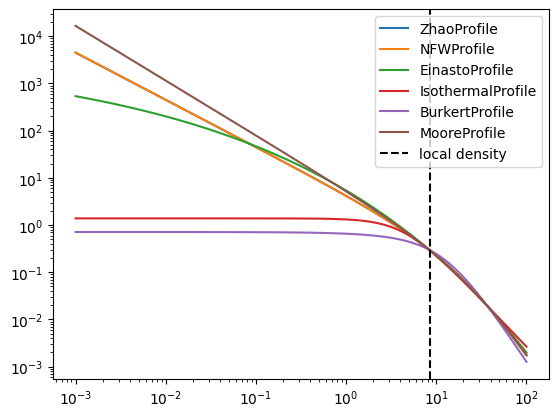

LOCAL_DENSITY: 0.3 GeV / cm3
DISTANCE_GC: 8.33 kpc


In [ ]:
profiles.DMProfile.__subclasses__()

for profile in profiles.DMProfile.__subclasses__():
    p = profile()
    p.scale_to_local_density()
    radii = np.logspace(-3, 2, 100) * u.kpc
    plt.plot(radii, p(radii), label=p.__class__.__name__)

plt.loglog()
plt.axvline(8.5, linestyle="dashed", color="black", label="local density")
plt.legend()
plt.show()

print("LOCAL_DENSITY:", profiles.DMProfile.LOCAL_DENSITY)
print("DISTANCE_GC:", profiles.DMProfile.DISTANCE_GC)

/tmp/ipykernel_805/4092050755.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


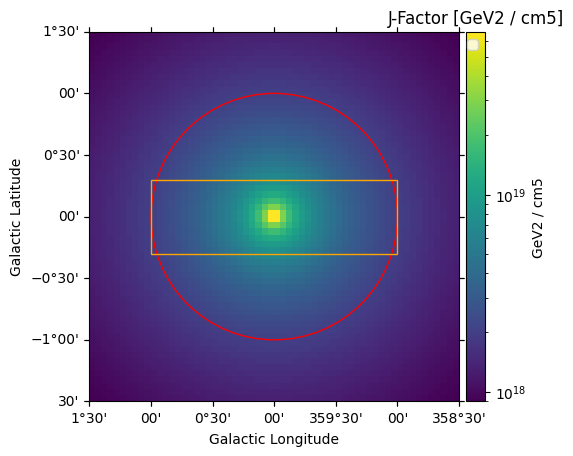

J-factor in 1 deg circle without the +/- 0.3 deg band around GC assuming a NFWProfile is 2.36e+21 GeV2 / cm5


In [ ]:
profile = profiles.NFWProfile(r_s=20 * u.kpc)

# Adopt standard values used in HESS
profiles.DMProfile.DISTANCE_GC = 8.5 * u.kpc
profiles.DMProfile.LOCAL_DENSITY = 0.39 * u.Unit("GeV / cm3")

profile.scale_to_local_density()

position = SkyCoord(0.0, 0.0, frame="galactic", unit="deg")
geom = WcsGeom.create(binsz=0.05, skydir=position, width=3.0, frame="galactic")

jfactory = JFactory(geom=geom, profile=profile, distance=profiles.DMProfile.DISTANCE_GC)
jfact = jfactory.compute_jfactor()

jfact_map = WcsNDMap(geom=geom, data=jfact.value, unit=jfact.unit)
plt.figure()
ax = jfact_map.plot(cmap="viridis", norm=LogNorm(), add_cbar=True)
plt.title(f"J-Factor [{jfact_map.unit}]")

# 1 deg circle usually used in H.E.S.S. analyses without the +/- 0.3 deg band around the plane
sky_reg = CircleSkyRegion(center=position, radius=1 * u.deg)
pix_reg = sky_reg.to_pixel(wcs=geom.wcs)
pix_reg.plot(ax=ax, facecolor="none", edgecolor="red", label="1 deg circle")

sky_reg_rec = RectangleSkyRegion(center=position, height=0.6 * u.deg, width=2 * u.deg)
pix_reg_rec = sky_reg_rec.to_pixel(wcs=geom.wcs)
pix_reg_rec.plot(ax=ax, facecolor="none", edgecolor="orange", label="+/- 0.3 deg band")

plt.legend()
plt.show()

# NOTE: https://arxiv.org/abs/1607.08142 quote 2.67e21
total_jfact = (
    pix_reg.to_mask().multiply(jfact).sum()
    - pix_reg_rec.to_mask().multiply(jfact).sum()
)
total_jfact = (
    pix_reg.to_mask().multiply(jfact).sum()
    - pix_reg_rec.to_mask().multiply(jfact).sum()
)
print(
    "J-factor in 1 deg circle without the +/- 0.3 deg band around GC assuming a "
    f"{profile.__class__.__name__} is {total_jfact:.3g}"
)